# Практическая работа: спутниковая океанология — мультисенсорный подход

**Цель:** исследовать временные изменения метеорологических параметров и пространственное распределение температуры поверхности моря (ТПМ) по предоставленным данным.

В работе используются `данные/September.xlsx` и `данные/sst.nc`. Для чтения NetCDF применён `h5py` (файл NetCDF-4 является контейнером HDF5); при желании его также можно открыть через `xarray` при установленном backend `netCDF4` или `h5netcdf`.



## 0. Импорт библиотек и настройка

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
DATA_DIR = Path('данные')
XLSX_PATH = DATA_DIR / 'September.xlsx'
NC_PATH = DATA_DIR / 'sst.nc'

for path in (XLSX_PATH, NC_PATH):
    if not path.exists():
        raise FileNotFoundError(f'Не найден файл: {path.resolve()}')
print('Файлы данных найдены.')

Файлы данных найдены.


## Задание 1. Временной ход температуры воздуха и атмосферного давления

Загружаем таблицу, проверяем типы данных и пропуски. Временные отметки сортируем по возрастанию, поскольку исходная таблица записана в обратном хронологическом порядке.

Размер таблицы: (120, 3)
Столбцы: ['Time', 'Temperature', 'Pressure']


,Time,Temperature,Pressure
0,2021-09-15 21:00:00,7.5,764.7
1,2021-09-15 18:00:00,9.6,763.4
2,2021-09-15 15:00:00,9.5,762.1
3,2021-09-15 12:00:00,6.6,760.5
4,2021-09-15 09:00:00,6.6,759.2


Типы данных:
 Time           datetime64[ns]
Temperature           float64
Pressure              float64
dtype: object
Количество пропусков:
 Time           0
Temperature    0
Pressure       0
dtype: int64


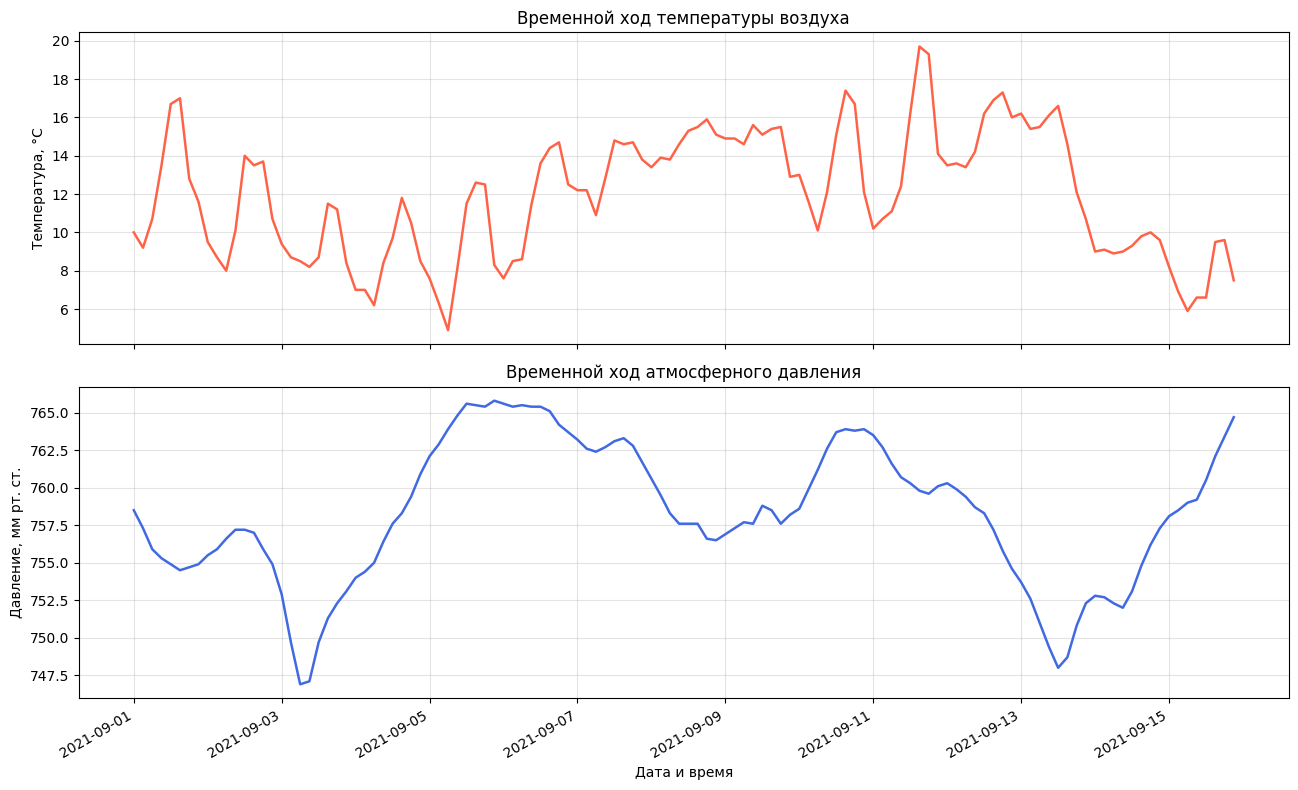

Период наблюдений: 2021-09-01 00:00:00 — 2021-09-15 21:00:00
Температура: от 4.9 до 19.7 °C
Давление: от 746.9 до 765.8 гПа


In [2]:
df = pd.read_excel(XLSX_PATH)
print('Размер таблицы:', df.shape)
print('Столбцы:', df.columns.tolist())
display(df.head())
print('Типы данных:\n', df.dtypes)
print('Количество пропусков:\n', df.isna().sum())

# Приведение времени к datetime и сортировка
df['Time'] = pd.to_datetime(df['Time'])
df = df.sort_values('Time').reset_index(drop=True)

# В таблице температура указана в °C, давление — в мм рт. ст. (по диапазону исходных значений).
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df['Time'], df['Temperature'], color='tomato', linewidth=1.8)
axes[0].set_title('Временной ход температуры воздуха')
axes[0].set_ylabel('Температура, °C')
axes[0].grid(True, alpha=0.35)

axes[1].plot(df['Time'], df['Pressure'], color='royalblue', linewidth=1.8)
axes[1].set_title('Временной ход атмосферного давления')
axes[1].set_ylabel('Давление, мм рт. ст.')
axes[1].set_xlabel('Дата и время')
axes[1].grid(True, alpha=0.35)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print(f"Период наблюдений: {df['Time'].min()} — {df['Time'].max()}")
print(f"Температура: от {df['Temperature'].min():.1f} до {df['Temperature'].max():.1f} °C")
print(f"Давление: от {df['Pressure'].min():.1f} до {df['Pressure'].max():.1f} гПа")

### Краткий вывод по заданию 1

В наборе содержится 120 наблюдений за период **1–15 сентября 2021 года** с трёхчасовым шагом. По графикам можно проследить синхронные и разновременные изменения температуры воздуха и давления. Числовые диапазоны выводятся кодом выше; их интерпретацию следует делать с учётом того, что это короткий период наблюдений.

## Задание 2. Горизонтальное распределение температуры поверхности моря

### 2.1. Открытие NetCDF и описание переменных

Выводим переменные, их размерности и единицы измерения. В файле координатная сетка имеет шаг 0,25°: 720 широтных и 1440 долготных узлов.

In [3]:
with h5py.File(NC_PATH, 'r') as nc:
    print('Переменные и размерности:')
    for name, obj in nc.items():
        if isinstance(obj, h5py.Dataset):
            units = obj.attrs.get('units', 'не указаны')
            if isinstance(units, bytes):
                units = units.decode('utf-8')
            print(f'{name:8s} shape={obj.shape}, dtype={obj.dtype}, units={units}')

    print('\nГлобальные атрибуты:')
    for key in ['title', 'id', 'time_coverage_start', 'time_coverage_end']:
        value = nc.attrs.get(key, '')
        if isinstance(value, bytes): value = value.decode('utf-8')
        print(f'{key}: {value}')

Переменные и размерности:
anom     shape=(1, 1, 720, 1440), dtype=int16, units=Celsius
err      shape=(1, 1, 720, 1440), dtype=int16, units=Celsius
ice      shape=(1, 1, 720, 1440), dtype=int16, units=%
lat      shape=(720,), dtype=float32, units=degrees_north
lon      shape=(1440,), dtype=float32, units=degrees_east
sst      shape=(1, 1, 720, 1440), dtype=int16, units=Celsius
time     shape=(1,), dtype=float32, units=days since 1978-01-01 12:00:00
zlev     shape=(1,), dtype=float32, units=meters

Глобальные атрибуты:
title: NOAA/NCEI 1/4 Degree Daily Optimum Interpolation Sea Surface Temperature (OISST) Analysis, Version 2.1 - Final
id: oisst-avhrr-v02r01.19810901.nc
time_coverage_start: 1981-09-01T00:00:00Z
time_coverage_end: 1981-09-01T23:59:59Z


### 2.2. Чтение температуры, масштабирование и проверка единиц

Важно: согласно метаданным именно этого файла, переменная `sst` уже имеет единицы **Celsius**. Значения хранятся как целые числа с `scale_factor = 0.01`; поэтому сначала применяется масштабирование. Перевод из Кельвинов в градусы Цельсия выполняется только если единицы в метаданных действительно указаны как Kelvin: \(T_{°C}=T_K-273.15\). Таким образом, к данным этого файла повторно вычитать 273,15 нельзя.

In [4]:
with h5py.File(NC_PATH, 'r') as nc:
    raw_sst = nc['sst'][0, 0, :, :].astype('float32')
    lat = nc['lat'][:]
    lon = nc['lon'][:]
    sst_attrs = dict(nc['sst'].attrs)
    time_value = float(nc['time'][0])
    time_units = nc['time'].attrs['units']
    fill_value = float(np.asarray(sst_attrs['_FillValue']).squeeze())
    scale_factor = float(np.asarray(sst_attrs.get('scale_factor', 1.0)).squeeze())
    add_offset = float(np.asarray(sst_attrs.get('add_offset', 0.0)).squeeze())
    units = sst_attrs.get('units', b'')
    if isinstance(units, bytes): units = units.decode('utf-8')

# Маскирование пропусков и применение packed-data scale/offset
sst = np.where(raw_sst == fill_value, np.nan, raw_sst * scale_factor + add_offset)
if units.strip().lower() in {'kelvin', 'kelvins', 'k'}:
    sst_c = sst - 273.15
    units_label = '°C'
elif units.strip().lower() in {'celsius', 'degree_celsius', 'degrees_celsius', '°c'}:
    sst_c = sst.copy()
    units_label = '°C'
else:
    raise ValueError(f'Неизвестные единицы температуры: {units!r}')

# Дата задаётся в атрибуте времени: дни от указанной эпохи
# Для файла: days since 1978-01-01 12:00:00
origin = pd.Timestamp('1978-01-01 12:00:00')
map_date = origin + pd.to_timedelta(time_value, unit='D')
print('Единицы в файле:', units)
print('Scale factor:', scale_factor, '| Add offset:', add_offset)
print('Дата наблюдения:', map_date)
print('Размер массива SST:', sst_c.shape)
print(f'Диапазон SST: {np.nanmin(sst_c):.2f} — {np.nanmax(sst_c):.2f} °C')

Единицы в файле: Celsius
Scale factor: 0.009999999776482582 | Add offset: 0.0
Дата наблюдения: 1981-09-01 12:00:00
Размер массива SST: (720, 1440)
Диапазон SST: -1.80 — 33.74 °C


### 2.3. Выбор участка океана и построение карты

Для примера выбран прямоугольник в западной части Атлантики и Мексиканском заливе: **15–32° с.ш., 260–280° в.д.** (долготы в файле заданы в диапазоне 0–360°). Это произвольный регион, удовлетворяющий условию задания.

Размер выбранного фрагмента: (68, 80)
Диапазон координат: 15–32° с.ш., 260–280° в.д.


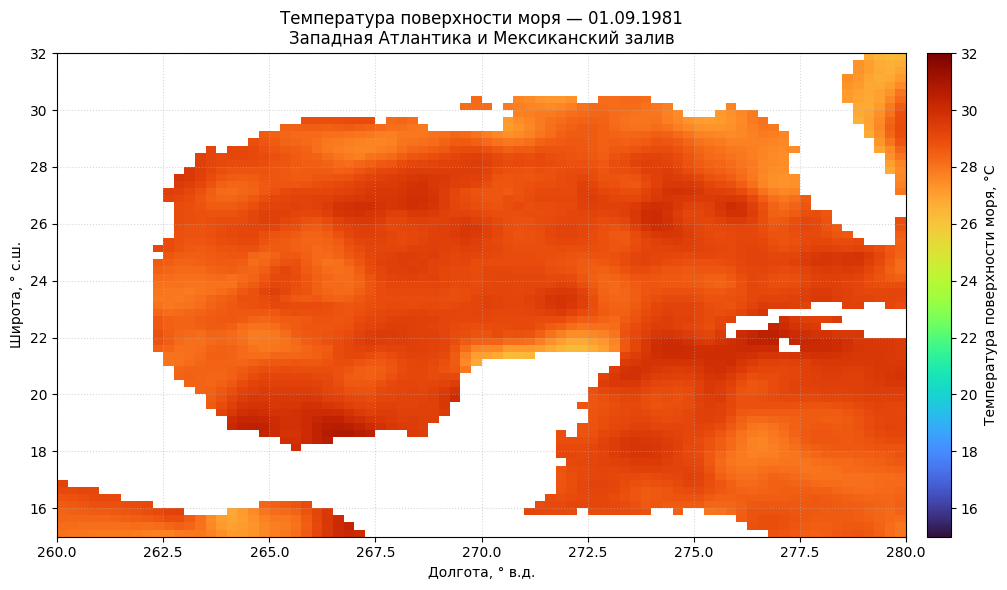

In [5]:
# Границы исследуемого района
lat_min, lat_max = 15, 32
lon_min, lon_max = 260, 280

lat_mask = (lat >= lat_min) & (lat <= lat_max)
lon_mask = (lon >= lon_min) & (lon <= lon_max)
region = sst_c[np.ix_(lat_mask, lon_mask)]
region_lat = lat[lat_mask]
region_lon = lon[lon_mask]

print('Размер выбранного фрагмента:', region.shape)
print(f'Диапазон координат: {lat_min}–{lat_max}° с.ш., {lon_min}–{lon_max}° в.д.')

fig, ax = plt.subplots(figsize=(11, 6))
mesh = ax.pcolormesh(region_lon, region_lat, region, shading='auto', cmap='turbo', vmin=15, vmax=32)
cb = fig.colorbar(mesh, ax=ax, pad=0.02)
cb.set_label('Температура поверхности моря, °C')
ax.set_xlabel('Долгота, ° в.д.')
ax.set_ylabel('Широта, ° с.ш.')
ax.set_title(f'Температура поверхности моря — {map_date:%d.%m.%Y}\nЗападная Атлантика и Мексиканский залив')
ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

### Вывод по заданию 2

Файл `sst.nc` содержит глобальный анализ температуры поверхности моря NOAA/NCEI OISST с пространственным разрешением 0,25°. Поле `sst` имеет размерность `(time, zlev, lat, lon)` = `(1, 1, 720, 1440)`. В метаданных единицы температуры обозначены как **Celsius**, а коэффициент масштабирования равен 0,01. Следовательно, после применения `scale_factor` температура уже выражена в °C; преобразование из Кельвинов для данного файла не требуется. На карте показано горизонтальное распределение ТПМ для выбранного участка на дату, закодированную в файле (**1 сентября 1981 года**).

**Общее заключение.** Выполнены оба пункта работы: построены временные графики температуры воздуха и атмосферного давления по Excel-таблице, исследованы структура и метаданные NetCDF-файла, обработано поле температуры и построена карта выбранного океанического района. Обратите внимание: временные периоды двух исходных наборов различаются (2021 и 1981 годы), поскольку файлы содержат независимые данные.